# 5. Evaluation
We evaluate the forest with L1 chosen in Modeling on the 1,298 later purchases
kept for the holdout. We use F1 as the main metric, then look at precision,
recall, accuracy and the errors to understand the result.

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

sns.set_theme(style="whitegrid")

## Load the model and holdout
We read the saved forest, the CSV with its selected variables and the cutoff
chosen in Modeling.
Both prepared tables use the parameters learned from development data.

In [2]:
target = "repeat_purchase_90d"
train = pd.read_csv("../data/prepared/train.csv", index_col="ID")
valid = pd.read_csv("../data/prepared/valid.csv", index_col="ID")
model = joblib.load("../results/development_model.joblib")
cols = pd.read_csv("../results/selected_features.csv")["feature"].tolist()
cutoff = pd.read_csv("../results/chosen_cutoff.csv")["cutoff"].item()

X_train = train.drop(columns=target)
y_train = train[target]
X_valid = valid.drop(columns=target)
y_valid = valid[target]

In [3]:
prob = model.predict_proba(X_valid[cols])[:, 1]
pred = (prob > cutoff).astype(int)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_valid)

## Compare with the baseline
We compare the forest and the majority-class baseline on the same purchases.
The baseline chooses its class using development labels.

In [4]:
scores = pd.DataFrame(index=["Baseline", "Random forest"])
scores["F1"] = [f1_score(y_valid, base_pred), f1_score(y_valid, pred)]
scores["precision"] = [precision_score(y_valid, base_pred, zero_division=0),
                       precision_score(y_valid, pred, zero_division=0)]
scores["recall"] = [recall_score(y_valid, base_pred, zero_division=0),
                    recall_score(y_valid, pred, zero_division=0)]
scores["accuracy"] = [accuracy_score(y_valid, base_pred), accuracy_score(y_valid, pred)]
scores.index.name = "model"
scores = scores.reset_index()
scores.round(4)

,model,F1,precision,recall,accuracy
0,Baseline,0.7525,0.6032,1.0000,0.6032
1,Random forest,0.7915,0.7209,0.8774,0.7211


With the 0.40 cutoff, the forest obtained **F1 0.7915**, compared with **0.7525**
for the baseline, a gain of about 3.9 percentage points. Precision is 0.7209 and
recall is 0.8774.
The baseline predicts a repeat purchase for everyone, giving recall 1 but
precision 0.6032. The forest improves precision while missing some positive cases.
Accuracy (0.7211) is lower than with the default 0.5 cutoff (0.7419), because
the lower cutoff accepts more false positives in exchange for higher recall.

Version 01, which still included `random_noise`, `Total Portes` and the purchase
year, scored F1 0.7778 here; version 02, without them but with the 0.5 cutoff,
scored 0.7818. We removed them for the reasons given in Data
Understanding and Data Preparation, and chose the cutoff on development folds;
we do not use these holdout differences to choose between the versions.

## Look at the errors
A false positive predicts a repeat purchase that does not happen within 90 days.
A false negative misses a customer who does buy again. The brief gives no
contact costs or margins, so we cannot calculate the financial effect of these errors.

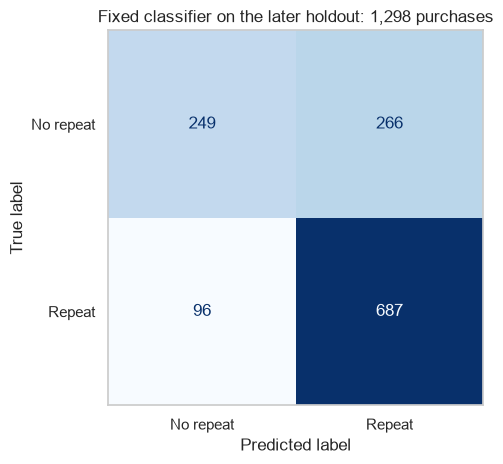

In [5]:
ConfusionMatrixDisplay.from_predictions(y_valid, pred, labels=[0, 1],
                                        display_labels=["No repeat", "Repeat"],
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.title("Fixed classifier on the later holdout: 1,298 purchases")
plt.tight_layout()
plt.show()

The forest correctly classified 687 repeat purchases and 249 non-repeat purchases.
It made 266 false-positive and 96 false-negative predictions in this holdout.

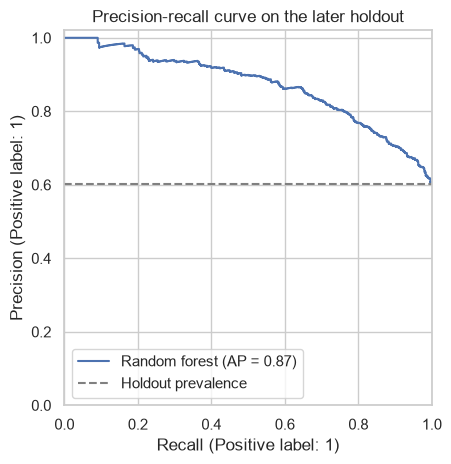

In [6]:
PrecisionRecallDisplay.from_predictions(y_valid, prob, name="Random forest")
plt.axhline(y_valid.mean(), color="grey", linestyle="--", label="Holdout prevalence")
plt.title("Precision-recall curve on the later holdout")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()

The curve shows the model's precision and recall at different thresholds.
We use the cutoff chosen on the development folds; we do not choose a cutoff
using this holdout. The average precision shown in the plot is different from Kaggle's F1.

## Compare customer groups
We separate customers seen in development from those absent from that period.
A customer absent from development can still have earlier purchase history.
We identify first purchases separately with `prior_purchase_count == 0`.

In [7]:
raw = pd.read_csv("../data/clean/train.csv", parse_dates=["purchase_date"])
raw = raw.set_index("ID")
meta = raw.loc[valid.index]
seen = meta["customer_id"].isin(raw.loc[train.index, "customer_id"])
first = meta["prior_purchase_count"] == 0

res = pd.DataFrame(index=valid.index)
res["actual"] = y_valid
res["prediction"] = pred
res["probability"] = prob

In [8]:
groups = [("Seen in development", seen), ("Unseen in development", ~seen),
          ("First purchase", first), ("Previous history", ~first)]
rows = []
for name, mask in groups:
    if mask.sum() > 0:
        y_group = res.loc[mask, "actual"]
        pred_group = res.loc[mask, "prediction"]
        pos = int(y_group.sum())
        tp = int(((y_group == 1) & (pred_group == 1)).sum())
        f1 = f1_score(y_group, pred_group, zero_division=0)
        rows.append([name, len(y_group), pos, tp, y_group.mean(), f1])
groups = pd.DataFrame(rows, columns=["group", "purchases", "positives",
                                    "true positives", "repeat share", "F1"])
groups.round(4)

,group,purchases,positives,true positives,repeat share,F1
0,Seen in development,1153,707,631,0.6132,0.8008
1,Unseen in development,145,76,56,0.5241,0.7000
2,First purchase,44,12,5,0.2727,0.4348
3,Previous history,1254,771,682,0.6148,0.7963


F1 is 0.8008 for customers seen in development and 0.7000 for those not seen.
The latter group has 145 purchases, of which 101 already have previous history.

Of the 44 first purchases, 12 were followed by another purchase within 90 days.
The model found 5 of them (F1 0.4348). With the default 0.5 cutoff it found none:
first purchases have no history, so their probabilities rarely exceed 0.5. The
lower cutoff helps, but this group remains the weakest. It is small, so we
should be careful about generalising this result.

These are two separate comparisons: seen/unseen in development and first/previous
purchases. The groups overlap across comparisons, so their counts cannot be added.

In [9]:
errors = res.loc[res["actual"] != res["prediction"]].copy()
errors["prior_purchase_count"] = meta.loc[errors.index, "prior_purchase_count"]
errors["days_since_previous_purchase"] = meta.loc[errors.index, "days_since_previous_purchase"]
errors.sort_values("probability", ascending=False).head(10).round(3)

,actual,prediction,probability,prior_purchase_count,days_since_previous_purchase
ID,,,,,
10006602,0,1,0.926,276.0,20.0
10007078,0,1,0.924,63.0,98.0
10004915,0,1,0.848,14.0,46.0
10003296,0,1,0.834,82.0,77.0
10001929,0,1,0.825,74.0,NaN
10006201,0,1,0.807,79.0,77.0
10005666,0,1,0.806,106.0,36.0
10007452,0,1,0.799,58.0,66.0
10003618,0,1,0.795,24.0,13.0


## Save the results
We save the metrics, predictions and group results so they can be checked
against the notebook and report.

In [10]:
scores.to_csv("../results/holdout_metrics.csv", index=False)
res.to_csv("../results/holdout_predictions.csv", index=True)
groups.to_csv("../results/holdout_groups.csv", index=False)

## Limits and next step
This holdout covers one later period. The earlier group notebook had already
explored the full training file, so it is not completely untouched. Customers
can appear in several rows, and purchase scores are not independent customer trials.

Cleaning assumes the supplied totals and purchase counts are reliable.
The customer table has no historical snapshots. Calendar variables and the
rare-category threshold need further comparison in the final project.
We keep the chosen model unchanged after this evaluation.

Next: [Deployment](06_Deployment.ipynb), where we train on all available dated
training purchases and create the Kaggle CSV. No Kaggle score has been checked yet.